# Partial-angle stacks: a simultaneous (AVO) inversion of the wedge

The other notebooks invert a single near stack. A near stack is almost blind
to shear properties: at 8° a 100 m/s change in shear velocity changes the
reflection about ten times less than the same change in P velocity. The S
impedance the inversion reports is then mostly the prior (the rock-physics
trend linking vs to vp), not the data.

Shear information comes from how the reflection changes with angle (the AVO
gradient). This notebook records the same gas-sand wedge as **three partial
stacks, 5-15°, 15-25° and 25-35°**, and inverts them together. Each stack has
its own wavelet and noise level; the forward model uses the **Aki-Richards**
linearisation, averaged over each stack's angle range, because at 30° and
beyond Delivery's small-angle form (θ² in place of sin²θ and tan²θ) is no
longer accurate.

We then ask: what do the far stacks add? To keep the comparison fair, the
"near-only" run inverts the *same* 5-15° data alone.

## Step 1: the inputs

In [1]:
import sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pydelivery import Inversion
from pydelivery.describe import show
from pydelivery.qc import plot_qc, plot_stack_qc, posterior_sections

sys.path.insert(0, ".")
from wedge_example import build_wedge, partial_stack_xml

ANGLES = [(5, 15), (15, 25), (25, 35)]
work = Path("partial_stacks_data")
truth = build_wedge(work, angles=ANGLES)          # same earth model and picks as synthetic_wedge.ipynb
(work / "near_only.xml").write_text(partial_stack_xml(ANGLES[:1]))
x, times = truth["x"], truth["times"]
Zp_true, Zs_true, stack_data = truth["Z_true"], truth["Zs_true"], truth["stack_data"]

inv_all = Inversion.from_files(work / "ModelDescription.xml", work / "priors.h5")
inv_near = Inversion.from_files(work / "near_only.xml", work / "priors.h5")
show(inv_all.cfg, groups=["seismic", "implied"]);

,seismic file,wavelet file,angles,offsets (m),reflector time (ms),stack velocity (m/s),noise RMS,window above/below (ms)
stack,,,,,,,,
5-15 deg,stack_5_15.h5,wavelet_5_15.h5,5-15° (rms 10.4°),-,-,-,0.01,wavelet / wavelet
15-25 deg,stack_15_25.h5,wavelet_15_25.h5,15-25° (rms 20.2°),-,-,-,0.01,wavelet / wavelet
25-35 deg,stack_25_35.h5,wavelet_25_35.h5,25-35° (rms 30.1°),-,-,-,0.01,wavelet / wavelet


The **seismic** table is the inputs summary: three stacks, each with its
own file, wavelet (Ricker, 30, 27 and 24 Hz: far stacks usually have lower
frequencies) and noise. The *rms* angle is what the reflectivity effectively
sees for a stack whose angles are spread evenly over its range.

The **implied properties** table shows why the far stacks matter: the gas
sand's reflection coefficient grows from about −0.12 at 5-15° to −0.18 at
25-35° (a class III AVO response), while brine sand's barely changes. How
fast it grows depends on the shear contrast.

Below: the three input stacks, and the amplitude at the top of the sand
against angle for one thick-sand trace.

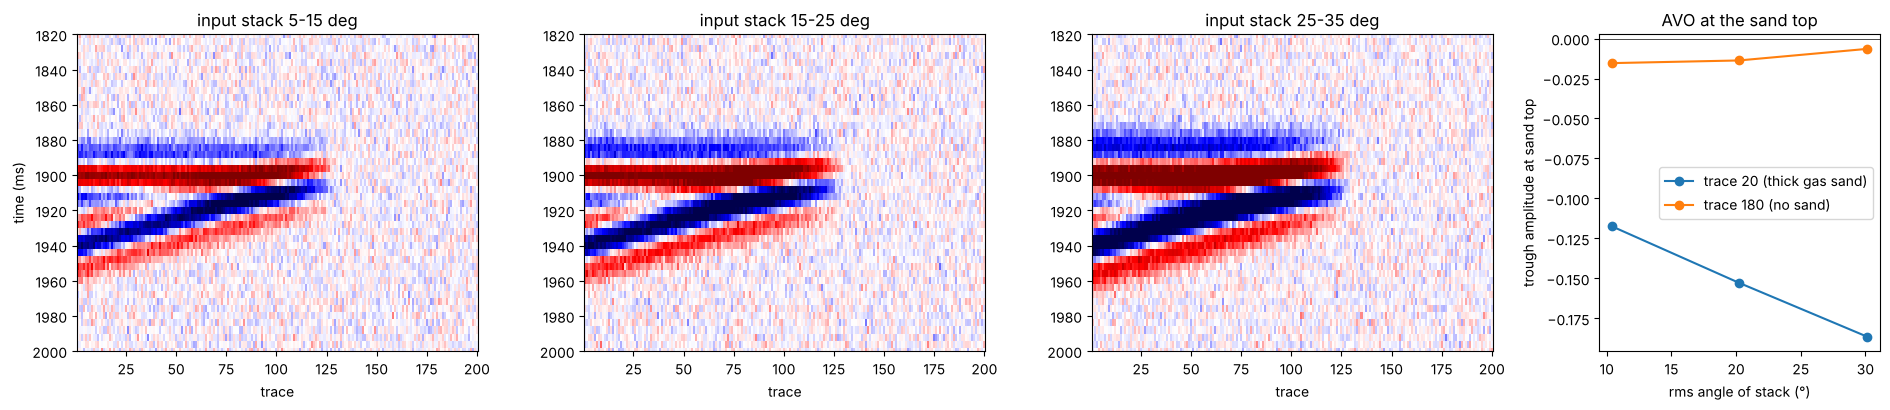

In [2]:
clip = np.percentile(np.abs(np.concatenate([d.ravel() for d in stack_data.values()])), 99)
ext = [0.5, len(x) + 0.5, 1000 * times[-1] + 2, 1000 * times[0] - 2]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 0.7]))
for ax, (name, d) in zip(axes, stack_data.items()):
    ax.imshow(d.T, aspect="auto", cmap="seismic_r", vmin=-clip, vmax=clip, extent=ext, interpolation="nearest")
    ax.set_title(f"input stack {name}"); ax.set_xlabel("trace"); ax.set_ylim(2000, 1820)
axes[0].set_ylabel("time (ms)")
j = np.argmin(np.abs(times - 1.900))
rms_angles = [np.degrees(np.sqrt(s.angle_terms()[0])) for s in inv_all.cfg.stacks]
for tr, lab in [(20, "trace 20 (thick gas sand)"), (180, "trace 180 (no sand)")]:
    amps = [stack_data[s.name][tr - 1, j - 2:j + 3].min() for s in inv_all.cfg.stacks]
    axes[3].plot(rms_angles, amps, "o-", label=lab)
axes[3].axhline(0, color="k", lw=0.5); axes[3].set_xlabel("rms angle of stack (°)")
axes[3].set_ylabel("trough amplitude at sand top"); axes[3].legend(); axes[3].set_title("AVO at the sand top")
plt.tight_layout(); plt.show()

## Step 2: invert near-only and all three stacks

The same settings as `synthetic_wedge.ipynb` (500 posterior samples per
trace, all cores), once with the 5-15° stack alone and once with all three.

In [3]:
results, run_time = {}, {}
for name, inv in [("near only (5-15°)", inv_near), ("three partial stacks", inv_all)]:
    start = time.time()
    results[name] = inv.run(n_samples=500, seed=1, n_jobs=-1)
    run_time[name] = time.time() - start
    print(f"{name}: {run_time[name]:.0f} s")
NEAR, ALL = results
cfgs = {NEAR: inv_near.cfg, ALL: inv_all.cfg}
sections = {n: [posterior_sections(results[n], times, stack=k) for k in range(len(cfgs[n].stacks))]
            for n in results}

near only (5-15°): 281 s


three partial stacks: 445 s


## Step 3: the standard QC, P and S impedance

The five-panel QC of the three-stack run, first for P impedance, then for
S impedance (true S impedance from the same earth model). The synthetic and
residual panels show the nearest stack; Step 4 shows all three.

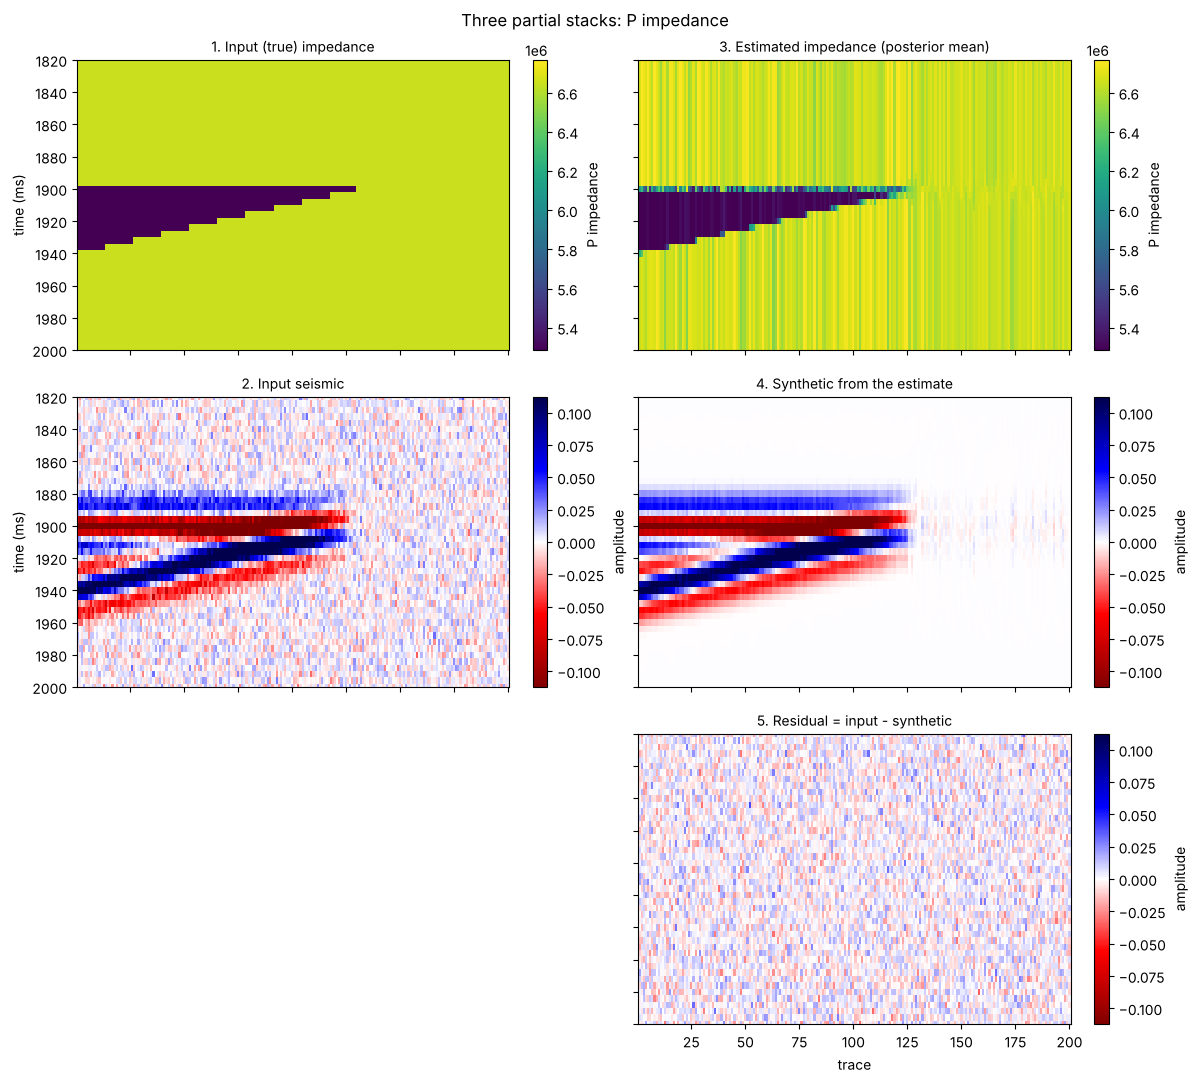

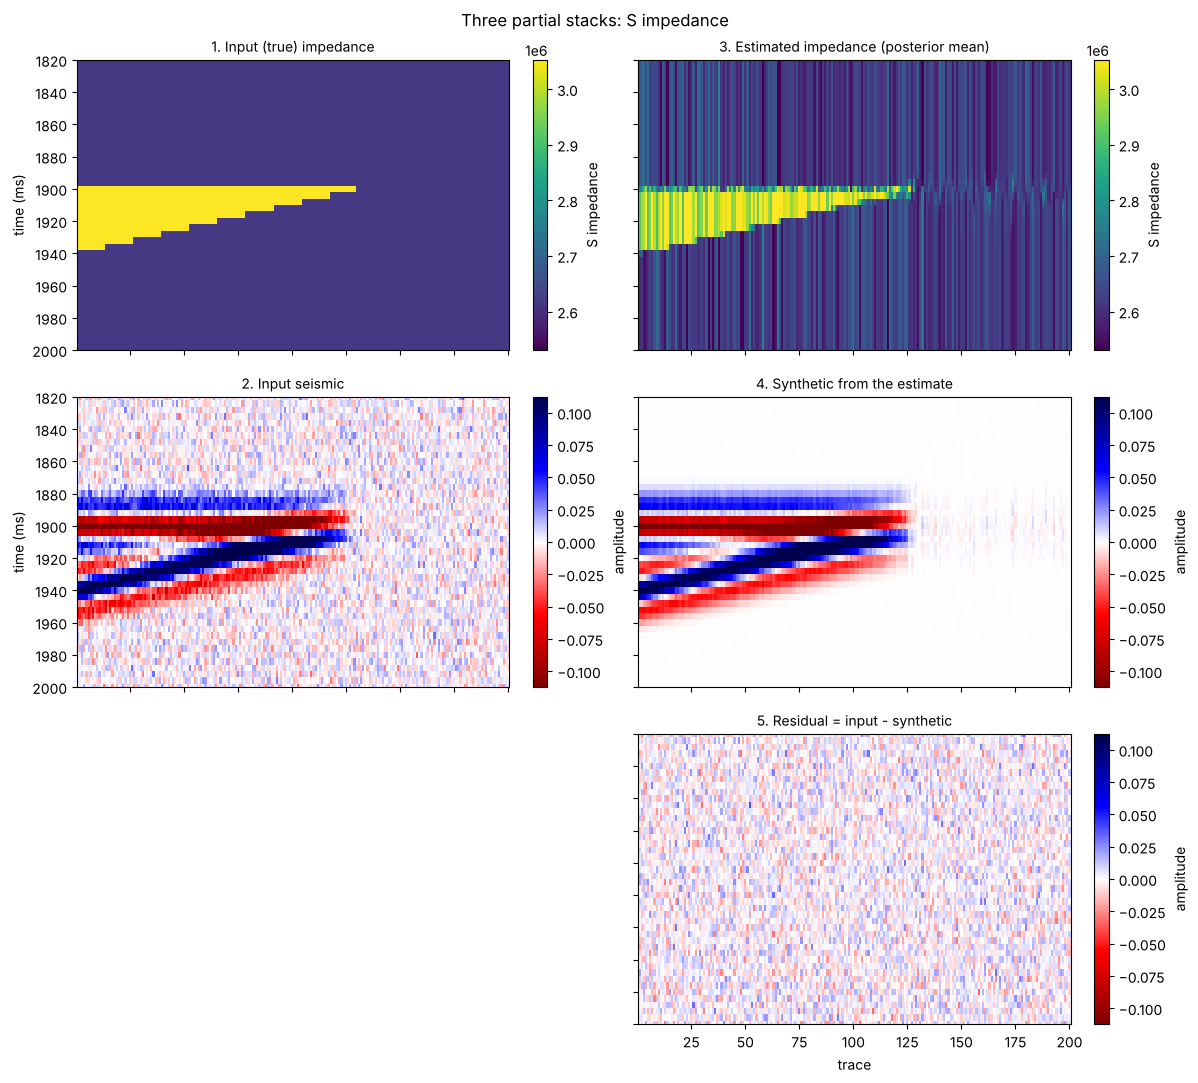

In [4]:
win = (1.82, 2.0)
s_all = sections[ALL][0]
fig, stats = plot_qc(times, stack_data["5-15 deg"], Zp_true, s_all["Zp_mean"], s_all["synthetic_mean"],
                     time_range=win, title="Three partial stacks: P impedance")
plt.show()
fig, _ = plot_qc(times, stack_data["5-15 deg"], Zs_true, s_all["Zs_mean"], s_all["synthetic_mean"],
                 time_range=win, title="Three partial stacks: S impedance", Z_label="S impedance")
plt.show()

## Step 4: the fit to every stack

Each row is one stack: the input, the synthetic of the posterior-mean model
for that stack, and the residual. A residual that looks like noise of RMS
0.01 on every stack means the model explains the AVO behaviour, not just the
near-stack amplitude.

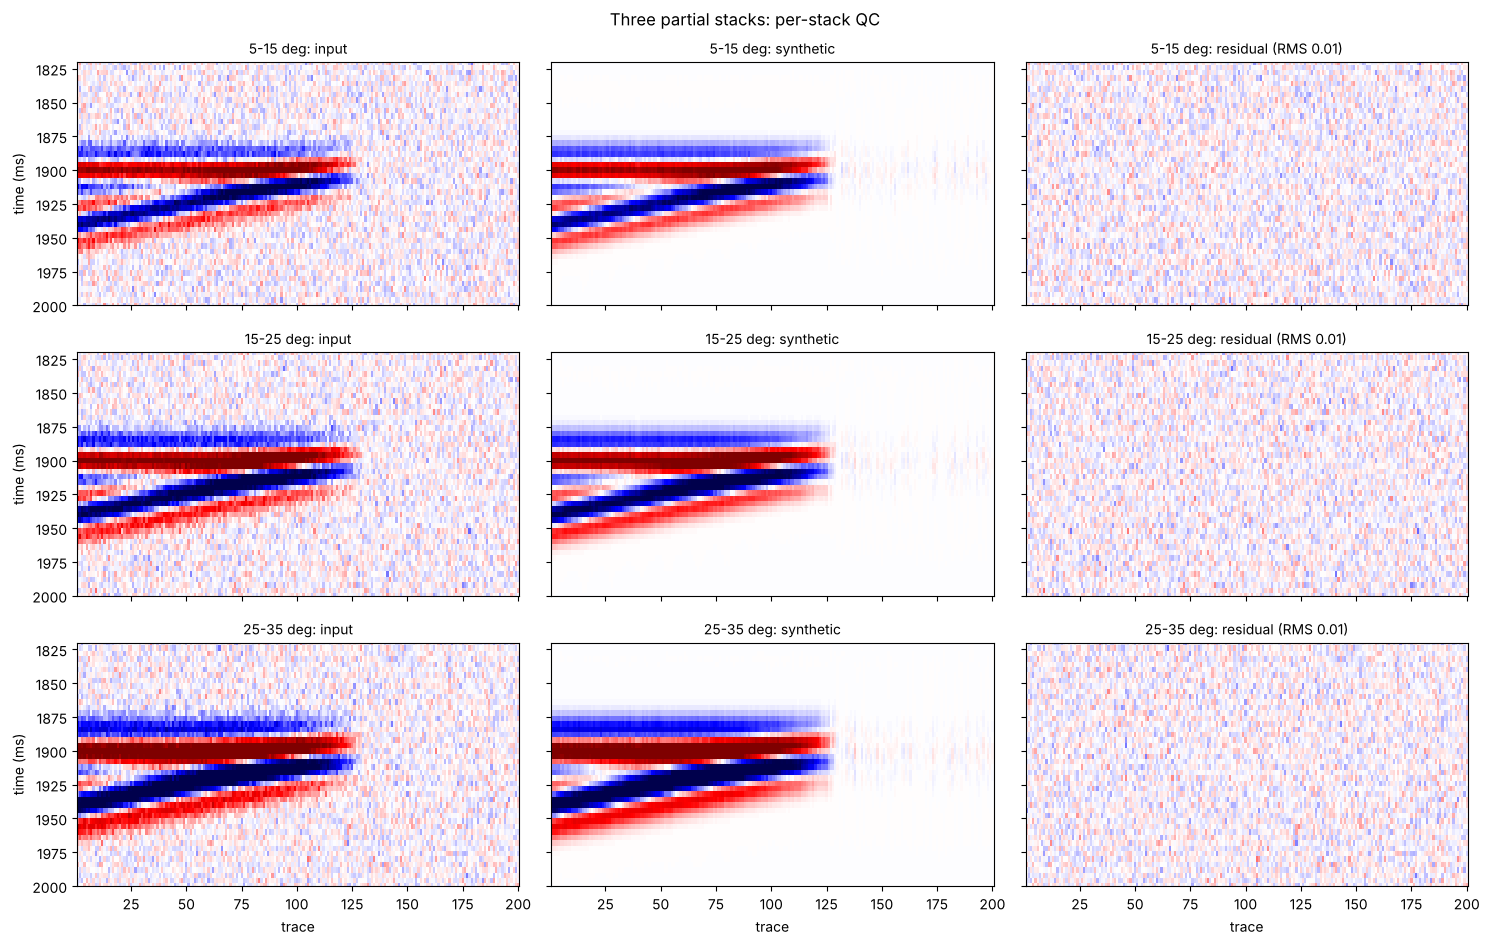

,residual RMS (noise added: 0.01)
5-15 deg,0.01
15-25 deg,0.01
25-35 deg,0.01


In [5]:
synth = {s.name: sections[ALL][k]["synthetic_mean"] for k, s in enumerate(inv_all.cfg.stacks)}
fig, rms = plot_stack_qc(times, stack_data, synth, time_range=win, title="Three partial stacks: per-stack QC")
plt.show()
pd.Series(rms, name="residual RMS (noise added: 0.01)").round(4).to_frame()

## Step 5: what the far stacks add

Seismic constrains *contrasts* across interfaces, so we measure uncertainty
on the contrast at the top of the sand and on the sand's vp/vs ratio (the
classic AVO fluid and lithology indicator), at the 129 traces where the sand
is present. Smaller posterior sd = more information from the data.

In [6]:
sand = truth["thick_true"] > 0
from pydelivery.qc import model_facies
facies = model_facies(inv_all.cfg)
gas = next(f for f in facies if f["name"] == "sand + gas")
vpvs_true = gas["Zp"] / gas["Zs"]

def sand_stats(res):
    out = {}
    s = [r.samples for r, ok in zip(res, sand) if ok]
    sd = lambda f: np.mean([np.std(f(q)) for q in s])          # noqa: E731
    out["posterior sd: P-impedance contrast at sand top"] = sd(lambda q: q["Z_eff"][:, 1] - q["Z_eff"][:, 0])
    out["posterior sd: S-impedance contrast at sand top"] = sd(lambda q: q["Zs_eff"][:, 1] - q["Zs_eff"][:, 0])
    out["posterior sd: sand vp/vs"] = sd(lambda q: q["vp_eff"][:, 1] / q["vs_eff"][:, 1])
    out["prior sd: sand vp/vs (from trends)"] = np.nan
    return out

table = pd.DataFrame({n: sand_stats(r) for n, r in results.items()})
table = table.drop("prior sd: sand vp/vs (from trends)")
for n, res in results.items():
    sec = sections[n][0]
    p_gas = np.array([r.fluid_probabilities()[1][4] for r in res])
    table.loc["RMS error of S impedance (window)", n] = np.sqrt(np.mean(
        ((sec["Zs_mean"] - Zs_true)[:, (times >= win[0]) & (times <= win[1])]) ** 2))
    table.loc["RMS error of P impedance (window)", n] = np.sqrt(np.mean(
        ((sec["Zp_mean"] - Zp_true)[:, (times >= win[0]) & (times <= win[1])]) ** 2))
    table.loc["mean P(gas), traces 1-100 (thick sand)", n] = p_gas[:100].mean()
    table.loc["mean P(gas), traces 101-129 (thin sand)", n] = p_gas[100:129].mean()
    table.loc["mean P(gas), traces 130-200 (no sand)", n] = p_gas[129:].mean()
    table.loc["run time (s)", n] = run_time[n]
table["ratio (three / near)"] = table[ALL] / table[NEAR]
table.style.format("{:.3g}")

,near only (5-15°),three partial stacks,ratio (three / near)
posterior sd: P-impedance contrast at sand top,2.11e+05,1.72e+05,0.817
posterior sd: S-impedance contrast at sand top,2.85e+05,1.66e+05,0.585
posterior sd: sand vp/vs,0.141,0.078,0.554
RMS error of S impedance (window),5.4e+04,5.77e+04,1.07
RMS error of P impedance (window),1.32e+05,1.14e+05,0.869
"mean P(gas), traces 1-100 (thick sand)",0.993,1,1.01
"mean P(gas), traces 101-129 (thin sand)",0.743,0.78,1.05
"mean P(gas), traces 130-200 (no sand)",0.0265,0.0172,0.648
run time (s),281,445,1.58


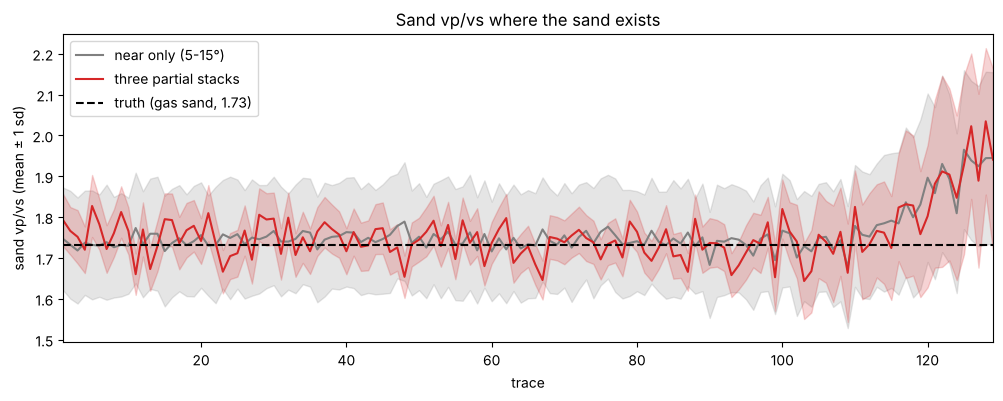

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
for (n, res), c in zip(results.items(), ["gray", "tab:red"]):
    m = np.array([np.mean(r.samples["vp_eff"][:, 1] / r.samples["vs_eff"][:, 1]) if ok else np.nan
                  for r, ok in zip(res, sand)])
    s = np.array([np.std(r.samples["vp_eff"][:, 1] / r.samples["vs_eff"][:, 1]) if ok else np.nan
                  for r, ok in zip(res, sand)])
    ax.fill_between(x, m - s, m + s, color=c, alpha=0.2); ax.plot(x, m, color=c, label=n)
ax.axhline(vpvs_true, color="k", ls="--", label=f"truth (gas sand, {vpvs_true:.2f})")
ax.set_xlim(1, 129); ax.set_xlabel("trace"); ax.set_ylabel("sand vp/vs (mean ± 1 sd)")
ax.legend(); ax.set_title("Sand vp/vs where the sand exists"); plt.show()

**What the numbers say** (posterior sd averaged over the 129 sand traces):

* **Shear contrast**: the sd of the S-impedance contrast at the sand top
  falls from 285,000 to 166,000 (×0.59). The sd of the sand's **vp/vs**
  almost halves, from 0.14 to 0.08 (×0.55). This is the information the
  near stack lacks: with 5-15° only, vp/vs stays close to its prior spread.
* **P contrast** also tightens a little (×0.82): the far stacks are extra
  independent measurements of the same interface.
* **Absolute S impedance** (RMS error against the truth) does *not* improve
  (54,000 vs 58,000). Seismic of any angle measures contrasts across
  interfaces, not absolute levels; those still come from the prior trends (or
  from wells, or the lateral prior of `lateral_continuity.ipynb`).
* **Fluids**: gas in the thick sand was already certain from the near stack
  (a bright, class III response). The far stacks add a little where the sand
  thins (P(gas) 0.74 → 0.78) and halve the false gas beyond the pinch-out
  (0.026 → 0.017).
* **Fit**: residual RMS is 0.010 on all three stacks, the noise added.
* **Cost**: 1.6× the run time for three stacks instead of one.

In the vp/vs plot, the three-stack band (red) is about half the width of the
near-only band (grey) and still covers the truth (1.73). Its mean wanders
more from trace to trace, because each trace's vp/vs now follows that
trace's own noisy far-stack amplitudes instead of sitting on the prior. Near
the pinch-out (traces beyond about 115) the sand is too thin to resolve and
both runs fall back towards the prior.

## Step 6: AI-SI cross-plot and K-means facies

The cross-plot of P impedance (AI) against S impedance (SI) of the
posterior-mean sections, classified by K-means into shale and gas sand (the
facies present, decided as in `lateral_continuity.ipynb`). With a near stack
alone, SI is largely predicted from AI by the rock-physics trend, so the
cross-plot mostly restates the prior. With partial stacks, SI carries its
own information.

clusters: ['shale', 'sand + gas']


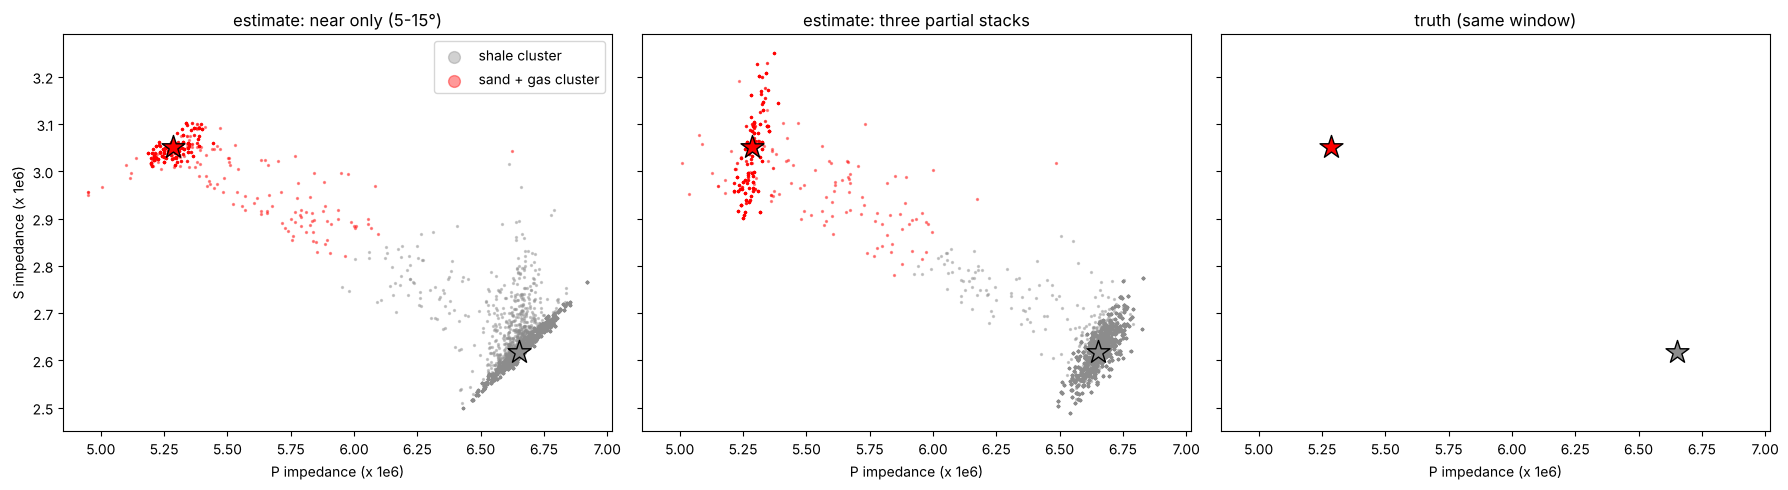

,near only (5-15°),three partial stacks
accuracy vs truth,0.991,0.991
true shale called sand,0.001,0.001
true gas sand found,0.908,0.902


In [8]:
from pydelivery.qc import classify_facies, facies_present

names = [f["name"] for f in facies]
SHALE, GAS = names.index("shale"), names.index("sand + gas")
w = (times >= 1.84) & (times <= 2.0)
tw = times[w]
true_lab = np.where((tw[None, :] >= truth["top_true"][:, None]) & (tw[None, :] < truth["base_true"][:, None]),
                    GAS, SHALE)
use = facies_present(results[NEAR], facies, layer=1)
print("clusters:", [f["name"] for f in use])
km = {}
for n in results:
    sec = sections[n][0]
    lab, centres, nearest = classify_facies(sec["Zp_mean"][:, w], sec["Zs_mean"][:, w], use)
    km[n] = dict(lab=np.array([facies.index(f) for f in use])[lab], Zp=sec["Zp_mean"][:, w],
                 Zs=sec["Zs_mean"][:, w])

colour = {SHALE: "0.55", GAS: "red"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (n, v) in zip(axes, km.items()):
    for f_idx in np.unique(v["lab"]):
        m = v["lab"] == f_idx
        ax.scatter(v["Zp"][m] / 1e6, v["Zs"][m] / 1e6, s=2, alpha=0.4, color=colour[f_idx],
                   label=f"{names[f_idx]} cluster")
    ax.set_title(f"estimate: {n}")
axes[2].scatter(Zp_true[:, w].ravel() / 1e6, Zs_true[:, w].ravel() / 1e6, s=2, alpha=0.4,
                c=np.where(true_lab.ravel() == GAS, "red", "0.55"))
axes[2].set_title("truth (same window)")
for ax in axes:
    for f in facies:
        if f["name"] in ("shale", "sand + gas"):
            ax.scatter(f["Zp"] / 1e6, f["Zs"] / 1e6, marker="*", s=300, color=colour[names.index(f["name"])],
                       edgecolor="k", zorder=5)
    ax.set_xlabel("P impedance (x 1e6)")
axes[0].set_ylabel("S impedance (x 1e6)"); axes[0].legend(markerscale=6); plt.tight_layout(); plt.show()

def scores(lab):
    return {"accuracy vs truth": (lab == true_lab).mean(),
            "true shale called sand": (lab[true_lab == SHALE] != SHALE).mean(),
            "true gas sand found": (lab[true_lab == GAS] == GAS).mean()}
pd.DataFrame({n: scores(v["lab"]) for n, v in km.items()}).style.format("{:.3f}")

**Reading the cross-plots.** In the *near-only* run the shale cloud lies on
a thin diagonal line, and the gas-sand points sit tightly on the prior-mean
star. That tidy look is the rock-physics trend, not the data: S impedance is
predicted from P impedance, so AI and SI move together. A cross-plot like
this cannot show anything that a plot of AI alone does not.

With *three partial stacks* the shale cloud widens into a blob and the gas
sand spreads vertically: S impedance now departs from the trend where the
far-stack amplitudes say it should (and, with noise of 0.01, where the noise
pushes it). The cross-plot now shows two independent measurements, which is
what makes AI-SI (or vp/vs) facies work worth doing.

**K-means** gives the same answer for both runs (99 % of samples right; 90-91 %
of true gas-sand samples found, the misses being at the thin end of the wedge).
Here gas sand is so much softer than shale that P impedance alone separates
them. Partial stacks matter when it does not: brine sand against shale (same
AI, different SI), or low-saturation against commercial gas.

## Summary

* `pydelivery` now inverts any number of stacks, defined by angle range
  (`<min_angle>`, `<max_angle>`) or by offsets, each with its own wavelet and
  noise, with Aki-Richards reflectivity for far angles.
* Partial stacks to 35° roughly halve the uncertainty in shear contrast and
  vp/vs on this wedge; with a near stack alone S impedance is mostly prior.
* They do not fix absolute impedance levels; that needs prior, well or
  lateral information.
* Next useful experiment: a brine-sand or low-saturation-gas case, where
  the near stack is ambiguous and the far stacks should decide the fluid.